# 123 · Your own evaluation suite: robustness of ACT / Diffusion / Flow to camera, lighting, texture and friction changes

In [1]:
import os, json, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop
from vlacourse.torch_data import TableTopDataset
from vlacourse.chunk_policies import ACT, DiffusionPolicy, FlowPolicy, ChunkPolicy
from vlacourse.eval_suite import run_suite, SUITE

from vlacourse import scene_dataset
SCENE = "single"                    # TableTop scene tier (see vlacourse.SCENES)
DATA = scene_dataset(SCENE)          # 500 demos, recorded once with all CPU cores if missing
CK = "../S08_Generative_Action_Heads/checkpoints"
from vlacourse import need; [need(f"{CK}/{n}.pt", f"S08 notebook {k}") for n, k in [("act", 74), ("diffusion", 78), ("flow", 81)]]
device = "cuda" if torch.cuda.is_available() else "cpu"
H = 16

def load(cls, name):
    net = cls(horizon=H); net.load_state_dict(torch.load(f"{CK}/{name}.pt", map_location=device)); return net.to(device).eval()

In [2]:
ds = TableTopDataset(DATA, episodes=range(450), horizon=H)
env = TableTop(scene=SCENE, cameras=("front", "wrist"), image_size=(128, 128), seed=0)
policies = {"ACT": ChunkPolicy(load(ACT, "act"), ds, env, device, ensemble=True),
            "Diffusion": ChunkPolicy(load(DiffusionPolicy, "diffusion"), ds, env, device, execute=8, nfe=10),
            "Flow": ChunkPolicy(load(FlowPolicy, "flow"), ds, env, device, execute=8, nfe=4)}
results = {}
for name, pol in policies.items():
    results[name] = run_suite(env, pol, n_episodes=30)
    print(name, {k: round(v["success"], 2) for k, v in results[name].items()})

vlacourse/chunk_policies.py:76: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  enc = lambda: nn.TransformerEncoder(nn.TransformerEncoderLayer(d, 8, 4 * d, 0.1, batch_first=True, norm_first=True), layers)


ACT {'nominal': 0.97, 'camera +3 cm': 0.93, 'camera +6 cm / lower': 0.9, 'dim light (x0.5)': 0.8, 'bright light (x1.6)': 0.77, 'grey table': 0.57, 'slippery cubes (μ=0.5)': 0.97}


Diffusion {'nominal': 0.97, 'camera +3 cm': 0.93, 'camera +6 cm / lower': 0.9, 'dim light (x0.5)': 0.93, 'bright light (x1.6)': 0.73, 'grey table': 0.7, 'slippery cubes (μ=0.5)': 0.9}


Flow {'nominal': 0.97, 'camera +3 cm': 1.0, 'camera +6 cm / lower': 1.0, 'dim light (x0.5)': 0.83, 'bright light (x1.6)': 0.87, 'grey table': 0.73, 'slippery cubes (μ=0.5)': 0.97}


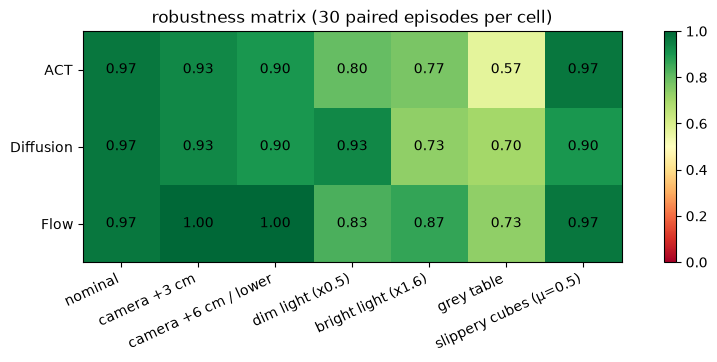

In [3]:
conds = [p.name for p in SUITE]
M = np.array([[results[n][c]["success"] for c in conds] for n in policies])
plt.figure(figsize=(11, 3)); plt.imshow(M, cmap="RdYlGn", vmin=0, vmax=1)
plt.xticks(range(len(conds)), conds, rotation=25, ha="right"); plt.yticks(range(len(policies)), list(policies))
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        plt.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center")
plt.title("robustness matrix (30 paired episodes per cell)"); plt.colorbar(); plt.show()

In [4]:
os.makedirs("results", exist_ok=True)
json.dump({n: {c: dict(success=results[n][c]["success"], ci=results[n][c]["ci"]) for c in conds} for n in policies}, open("results/robustness_matrix.json", "w"), indent=1)
drops = {n: {c: results[n]["nominal"]["success"] - results[n][c]["success"] for c in conds[1:]} for n in policies}
for n, d in drops.items():
    worst = max(d, key=d.get)
    print(f"{n:9s} largest drop: {worst} (-{d[worst]:.2f})")

ACT       largest drop: grey table (-0.40)
Diffusion largest drop: grey table (-0.27)
Flow      largest drop: grey table (-0.23)


### Watch it: one policy, three worlds
The same policy and episode under nominal conditions, a moved camera and dim light.

In [5]:
from vlacourse import showcase as sc
from vlacourse.eval_suite import _restore_all
def perturbed(fn):
    return lambda e: (_restore_all(e), fn(e))
sfx = {p.name: p.apply_fn for p in SUITE}
pol = policies["Flow"]
sc.compare(env, {"nominal": pol, "camera moved 6 cm": pol, "dim light": pol}, seed=200_002, size=(300, 400),
           per_policy_kw={"nominal": dict(on_reset=perturbed(sfx["nominal"])), "camera moved 6 cm": dict(on_reset=perturbed(sfx["camera +6 cm / lower"])),
                          "dim light": dict(on_reset=perturbed(sfx["dim light (x0.5)"]))}, title="123 one policy, three worlds")
_restore_all(env)

123 one policy, three worlds: nominal: success | camera moved 6 cm: failed | dim light: failed
